# 03 — Phân tích chất lượng dữ liệu

Notebook này dùng lại các hàm trong `src.data` và `src.utils` để nạp dữ liệu, kiểm tra các rule chất lượng, phân tích missingness và tạo các cờ dữ liệu. Quy tắc được quản lý tại `configs/data_quality.yaml`; không triển khai lại logic xử lý chính trong notebook.

> Dữ liệu trong dự án là synthetic, kết quả không đại diện cho khách hàng thực.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd

# Hỗ trợ chạy notebook khi working directory là thư mục dự án hoặc notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "configs" / "config.yaml").is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "configs" / "config.yaml").is_file():
    raise FileNotFoundError("Không tìm thấy configs/config.yaml từ working directory hiện tại.")

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data.clean import add_missing_flags, apply_entry_error_rules, handle_outliers
from src.data.load import load_raw
from src.data.validate import load_data_quality_config, run_rules
from src.utils.config import load_config

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)

## 1. Nạp cấu hình và dữ liệu

`load_raw` kiểm tra schema, chuyển kiểu dữ liệu và lưu bản interim Parquet theo thiết kế của pipeline.

In [2]:
config = load_config(PROJECT_ROOT / "configs" / "config.yaml")

# Chuẩn hóa đường dẫn tương đối theo gốc repository để notebook chạy ổn định.
for key in ("raw_path", "interim_path"):
    configured_path = Path(config["data"][key])
    if not configured_path.is_absolute():
        config["data"][key] = str(PROJECT_ROOT / configured_path)

quality_config_path = Path(config["data_quality"]["config_path"])
if not quality_config_path.is_absolute():
    quality_config_path = PROJECT_ROOT / quality_config_path
quality_config = load_data_quality_config(quality_config_path)

raw_df = load_raw(config)
print(f"Số dòng: {len(raw_df):,} | Số cột: {raw_df.shape[1]}")
display(raw_df.head())
display(raw_df.dtypes.rename("dtype").to_frame())

{"timestamp": "2026-11-02T14:30:54.413966+00:00", "level": "INFO", "logger": "src.utils.io", "message": "Reading CSV: e:\\Personal Project\\Data science_analyze finance\\data\\raw\\synthetic_finance_20250901.csv"}
{"timestamp": "2026-11-02T14:30:57.906160+00:00", "level": "INFO", "logger": "src.utils.io", "message": "Wrote Parquet atomically: e:\\Personal Project\\Data science_analyze finance\\data\\interim\\customers.parquet"}
{"timestamp": "2026-11-02T14:30:57.907177+00:00", "level": "INFO", "logger": "src.data.load", "message": "Loaded 750000 customer records from e:\\Personal Project\\Data science_analyze finance\\data\\raw\\synthetic_finance_20250901.csv"}


Số dòng: 750,000 | Số cột: 23


,customer_id,age,credit_score,income,employment_years,employment_status,education_level,marital_status,home_ownership,region,account_age_months,num_credit_cards,num_loans,late_payment_months,monthly_spending,credit_utilization,debt_to_income,savings_rate,investment_value,account_creation_date,last_transaction_date,credit_risk,fraud_risk_score
0,FN0000001,61,748,33027.32,3.1,Self-employed,Some College,Single,Mortgage,West,33,2,2,1,80.0,0.388,0.03,0.369,7404.55,2023-04-07,2024-12-12,0,0.61
1,FN0000002,39,661,42965.71,4.4,Self-employed,Some College,Single,Mortgage,West,32,2,1,4,674.9,0.435,0.188,0.281,9356.3,2022-04-30,2024-12-21,0,0.386
2,FN0000003,53,547,22000.0,82.0,Part-time,High School,Single,Rent,Northeast,14,2,3,2,976.7,0.295,0.533,0.232,7525.19,2022-11-18,2024-12-18,2,0.446
3,FN0000004,37,727,43531.06,3.6,Self-employed,Some College,Single,Mortgage,Midwest,11,1,0,1,80.0,0.261,0.03,0.257,20811.1,2021-05-27,2024-12-26,0,0.424
4,FN0000005,41,636,22956.16,3.7,Part-time,Some College,Married,Rent,Southeast,11,3,0,3,555.69,0.484,0.29,0.248,2863.83,2024-02-15,2024-12-19,1,0.443


,dtype
customer_id,string[python]
age,Int64
credit_score,Int64
income,Float64
employment_years,Float64
employment_status,category
education_level,category
marital_status,category
home_ownership,category
region,category


## 2. Tổng quan missingness

Bảng dưới đây chỉ thống kê giá trị thiếu; chưa điền hoặc loại bỏ dữ liệu.

,missing_count,missing_rate
column,,
savings_rate,5766,0.77%
monthly_spending,5227,0.70%
credit_utilization,5222,0.70%
debt_to_income,5182,0.69%
investment_value,568,0.08%
income,530,0.07%
age,0,0.00%
education_level,0,0.00%
employment_status,0,0.00%


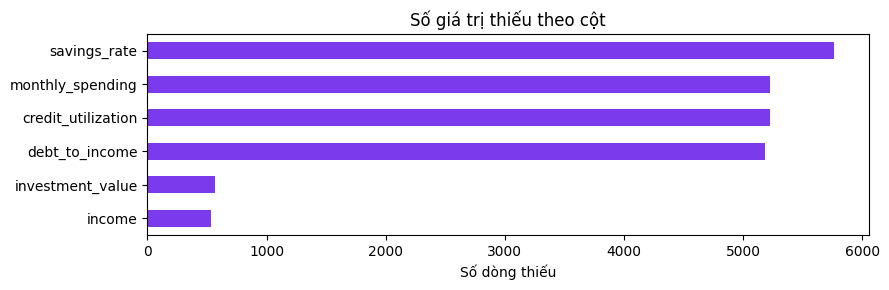

In [3]:
missingness = pd.DataFrame(
    {
        "missing_count": raw_df.isna().sum(),
        "missing_rate": raw_df.isna().mean(),
    }
).rename_axis("column").sort_values("missing_count", ascending=False)
display(missingness.style.format({"missing_rate": "{:.2%}"}))

missing_columns = missingness.index[missingness["missing_count"] > 0].tolist()
if missing_columns:
    missing_plot = missingness.loc[missing_columns].sort_values("missing_count")
    ax = missing_plot["missing_count"].plot.barh(figsize=(9, max(3, 0.35 * len(missing_plot))), color="#7c3aed")
    ax.set(title="Số giá trị thiếu theo cột", xlabel="Số dòng thiếu", ylabel="")
    plt.tight_layout()
    plt.show()
else:
    print("Không có giá trị thiếu trong dữ liệu ban đầu.")

## 3. Kiểm tra các rule chất lượng

`run_rules` lấy rule từ cấu hình YAML và trả về số lượng/tỷ lệ vi phạm trên dữ liệu ban đầu.

{"timestamp": "2026-11-02T14:31:17.450510+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule customer_id_format found 0 violations"}
{"timestamp": "2026-11-02T14:31:17.467580+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule age_range found 0 violations"}
{"timestamp": "2026-11-02T14:31:17.483238+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule income_nonnegative found 0 violations"}
{"timestamp": "2026-11-02T14:31:17.500204+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule credit_score_range found 502 violations"}
{"timestamp": "2026-11-02T14:31:17.512875+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule employment_years_nonnegative found 0 violations"}
{"timestamp": "2026-11-02T14:31:17.527830+00:00", "level": "INFO", "logger": "src.data.validate", "message": "Rule account_age_nonnegative found 0 violations"}
{"timestamp": "2026-11-02T14:31:17.542399+00:00", "level": "IN

,rule,count,rate
0,many_credit_cards_outlier,12781,1.70%
1,late_payment_months_range,12510,1.67%
2,employment_years_outlier,12499,1.67%
3,high_income_outlier,699,0.09%
4,high_monthly_spending_outlier,513,0.07%
5,credit_score_range,502,0.07%
6,high_investment_value_outlier,200,0.03%
7,age_range,0,0.00%
8,customer_id_format,0,0.00%
9,employment_years_nonnegative,0,0.00%


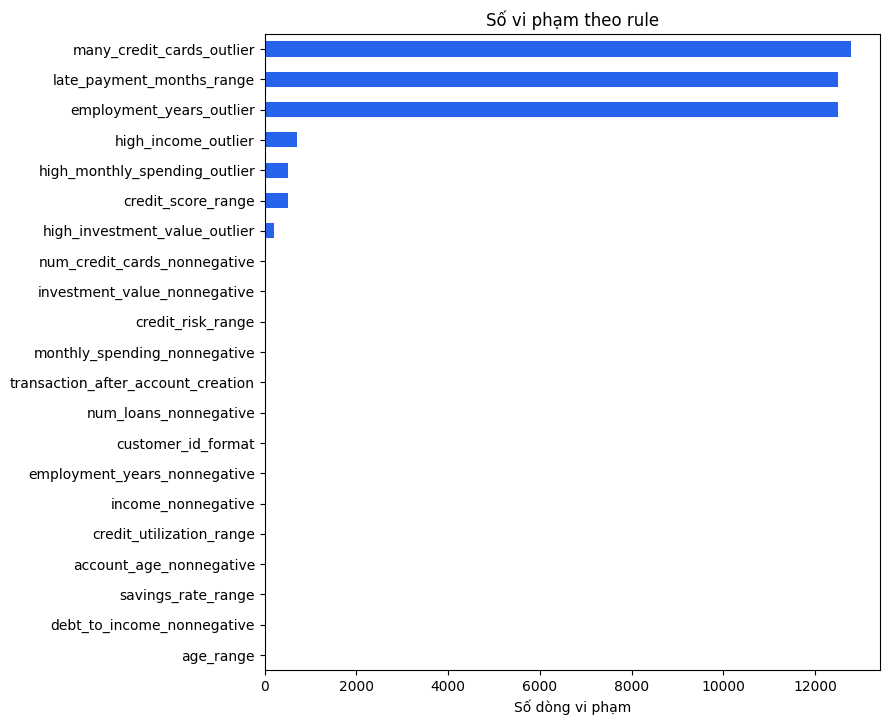

In [4]:
rule_results = run_rules(raw_df, quality_config)
rule_results_df = (
    pd.DataFrame.from_dict(rule_results, orient="index")
    .rename_axis("rule")
    .reset_index()
    .sort_values("count", ascending=False, ignore_index=True)
)
display(rule_results_df.style.format({"rate": "{:.2%}"}))

if not rule_results_df.empty:
    ax = rule_results_df.sort_values("count").plot.barh(
        x="rule", y="count", legend=False, figsize=(9, max(4, 0.35 * len(rule_results_df))), color="#2563eb"
    )
    ax.set(title="Số vi phạm theo rule", xlabel="Số dòng vi phạm", ylabel="")
    plt.tight_layout()
    plt.show()

## 4. Làm sạch lỗi đầu vào và xác minh

`apply_entry_error_rules` chỉ thay các giá trị vi phạm rule có action `to_nan` bằng giá trị thiếu. Các rule này được chạy lại để xác minh sau bước làm sạch.

In [5]:
cleaned_df = apply_entry_error_rules(raw_df, quality_config)
post_clean_results = run_rules(cleaned_df, quality_config)
entry_rule_names = [rule["name"] for rule in quality_config["rules"] if rule["action"] == "to_nan"]
entry_error_check = pd.DataFrame.from_dict(post_clean_results, orient="index").rename_axis("rule")
entry_error_check = entry_error_check.loc[entry_error_check.index.isin(entry_rule_names)]
display(entry_error_check.style.format({"rate": "{:.2%}"}))

remaining_entry_errors = entry_error_check.index[entry_error_check["count"] > 0].tolist()
if remaining_entry_errors:
    raise ValueError(f"Vẫn còn vi phạm entry-error sau làm sạch: {remaining_entry_errors}")
print("Đã xác minh: không còn vi phạm ở các rule action=to_nan.")

{"timestamp": "2026-11-02T14:31:27.162276+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 0 invalid customer_id values to missing"}
{"timestamp": "2026-11-02T14:31:27.181257+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 0 invalid age values to missing"}
{"timestamp": "2026-11-02T14:31:27.196429+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 0 invalid income values to missing"}
{"timestamp": "2026-11-02T14:31:27.214711+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 502 invalid credit_score values to missing"}
{"timestamp": "2026-11-02T14:31:27.229836+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 0 invalid employment_years values to missing"}
{"timestamp": "2026-11-02T14:31:27.245697+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Set 0 invalid account_age_months values to missing"}
{"timestamp": "2026-11-02T14:31:27.261499+00:00", "level": "INFO", "logger": "sr

,count,rate
rule,,
customer_id_format,0,0.00%
age_range,0,0.00%
income_nonnegative,0,0.00%
credit_score_range,0,0.00%
employment_years_nonnegative,0,0.00%
account_age_nonnegative,0,0.00%
monthly_spending_nonnegative,0,0.00%
credit_utilization_range,0,0.00%
num_credit_cards_nonnegative,0,0.00%


Đã xác minh: không còn vi phạm ở các rule action=to_nan.


## 5. Gắn cờ outlier và missingness

`handle_outliers` giữ nguyên giá trị quan sát và thêm cột cờ; `add_missing_flags` tạo cờ cho các cột còn giá trị thiếu.

In [6]:
outlier_df = handle_outliers(cleaned_df, quality_config)
final_df = add_missing_flags(outlier_df)

outlier_flag_columns = [column for column in final_df if column.endswith("_outlier_flag")]
missing_flag_columns = [column for column in final_df if column.endswith("_missing_flag")]
flag_summary = pd.DataFrame(
    {
        "flag_type": ["outlier", "missingness"],
        "flag_columns": [len(outlier_flag_columns), len(missing_flag_columns)],
        "flagged_rows": [
            int(final_df[outlier_flag_columns].any(axis=1).sum()) if outlier_flag_columns else 0,
            int(final_df[missing_flag_columns].any(axis=1).sum()) if missing_flag_columns else 0,
        ],
    }
)
display(flag_summary)
print(f"Kích thước sau khi thêm cờ: {final_df.shape}")
display(final_df.head())

{"timestamp": "2026-11-02T14:31:42.378046+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Flagged 12499 outliers in employment_years"}
{"timestamp": "2026-11-02T14:31:42.399053+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Flagged 699 outliers in income"}
{"timestamp": "2026-11-02T14:31:42.417435+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Flagged 513 outliers in monthly_spending"}
{"timestamp": "2026-11-02T14:31:42.436418+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Flagged 12781 outliers in num_credit_cards"}
{"timestamp": "2026-11-02T14:31:42.455383+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Flagged 200 outliers in investment_value"}
{"timestamp": "2026-11-02T14:31:42.554392+00:00", "level": "INFO", "logger": "src.data.clean", "message": "Added missingness flag for credit_score"}
{"timestamp": "2026-11-02T14:31:42.558139+00:00", "level": "INFO", "logger": "src.data.clean", "message": "

,flag_type,flag_columns,flagged_rows
0,outlier,5,26590
1,missingness,8,35103


Kích thước sau khi thêm cờ: (750000, 36)


,customer_id,age,credit_score,income,employment_years,employment_status,education_level,marital_status,home_ownership,region,account_age_months,num_credit_cards,num_loans,late_payment_months,monthly_spending,credit_utilization,debt_to_income,savings_rate,investment_value,account_creation_date,last_transaction_date,credit_risk,fraud_risk_score,employment_years_outlier_flag,income_outlier_flag,monthly_spending_outlier_flag,num_credit_cards_outlier_flag,investment_value_outlier_flag,credit_score_missing_flag,income_missing_flag,late_payment_months_missing_flag,monthly_spending_missing_flag,credit_utilization_missing_flag,debt_to_income_missing_flag,savings_rate_missing_flag,investment_value_missing_flag
0,FN0000001,61,748,33027.32,3.1,Self-employed,Some College,Single,Mortgage,West,33,2,2,1,80.0,0.388,0.03,0.369,7404.55,2023-04-07,2024-12-12,0,0.61,False,False,False,False,False,False,False,False,False,False,False,False,False
1,FN0000002,39,661,42965.71,4.4,Self-employed,Some College,Single,Mortgage,West,32,2,1,4,674.9,0.435,0.188,0.281,9356.3,2022-04-30,2024-12-21,0,0.386,False,False,False,False,False,False,False,False,False,False,False,False,False
2,FN0000003,53,547,22000.0,82.0,Part-time,High School,Single,Rent,Northeast,14,2,3,2,976.7,0.295,0.533,0.232,7525.19,2022-11-18,2024-12-18,2,0.446,True,False,False,False,False,False,False,False,False,False,False,False,False
3,FN0000004,37,727,43531.06,3.6,Self-employed,Some College,Single,Mortgage,Midwest,11,1,0,1,80.0,0.261,0.03,0.257,20811.1,2021-05-27,2024-12-26,0,0.424,False,False,False,False,False,False,False,False,False,False,False,False,False
4,FN0000005,41,636,22956.16,3.7,Part-time,Some College,Married,Rent,Southeast,11,3,0,3,555.69,0.484,0.29,0.248,2863.83,2024-02-15,2024-12-19,1,0.443,False,False,False,False,False,False,False,False,False,False,False,False,False


## 6. Missingness theo nhóm

So sánh tỷ lệ thiếu theo tình trạng việc làm, nhóm thu nhập và nhãn rủi ro tín dụng (nếu dữ liệu có missingness). Đây là mô tả quan sát, không dùng để kết luận quan hệ nhân quả.

In [7]:
if missing_columns:
    income_bins = [*config["data_quality"]["income_bins"], float("inf")]
    diagnostic_df = raw_df.assign(
        income_bin=pd.cut(raw_df["income"], bins=income_bins, right=False)
    )
    for group_column in ("employment_status", "income_bin", "credit_risk"):
        if group_column not in diagnostic_df:
            continue
        grouped_rates = diagnostic_df.groupby(group_column, observed=True)[missing_columns].agg(
            lambda values: values.isna().mean()
        )
        print(f"Tỷ lệ thiếu theo {group_column}")
        display(grouped_rates.style.format("{:.2%}"))
else:
    print("Không có missingness để phân tích theo nhóm.")

Tỷ lệ thiếu theo employment_status


,savings_rate,monthly_spending,credit_utilization,debt_to_income,investment_value,income
employment_status,,,,,,
Full-time,0.75%,0.73%,0.74%,0.76%,0.00%,0.00%
Part-time,0.73%,0.76%,0.77%,0.75%,0.00%,0.00%
Retired,0.74%,0.77%,0.73%,0.75%,0.00%,0.00%
Self-employed,0.78%,0.76%,0.76%,0.74%,0.00%,0.00%
Unemployed,0.86%,0.30%,0.31%,0.28%,0.61%,0.56%


Tỷ lệ thiếu theo income_bin


,savings_rate,monthly_spending,credit_utilization,debt_to_income,investment_value,income
income_bin,,,,,,
"[0.0, 50000.0)",0.78%,0.67%,0.68%,0.67%,0.10%,0.00%
"[50000.0, 100000.0)",0.74%,0.74%,0.74%,0.74%,0.01%,0.00%
"[100000.0, 150000.0)",0.84%,0.89%,0.77%,0.81%,0.00%,0.00%
"[150000.0, inf)",0.76%,0.76%,0.68%,0.61%,0.00%,0.00%


Tỷ lệ thiếu theo credit_risk


,savings_rate,monthly_spending,credit_utilization,debt_to_income,investment_value,income
credit_risk,,,,,,
0,0.75%,0.74%,0.73%,0.74%,0.01%,0.01%
1,0.80%,0.72%,0.73%,0.69%,0.06%,0.06%
2,0.77%,0.63%,0.66%,0.63%,0.16%,0.14%
3,0.82%,0.50%,0.47%,0.49%,0.32%,0.32%


## Kết luận

- Các rule, thao tác làm sạch và gắn cờ trong notebook được import từ `src.data`.
- Bản dữ liệu đã nạp được lưu tại `data/interim/customers.parquet` theo cấu hình; `raw_df` giữ dữ liệu trước làm sạch, còn `final_df` là dataframe đã làm sạch và bổ sung cờ.
- Báo cáo HTML đầy đủ có thể được tạo bằng script hiện có: `python -m scripts.run_data_quality`.